In [1]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 16 — Round 6: SegFormer v6 = all 12 months + richer year statistics

**Why:** v5 gets one month + 4 year numbers (mean and spread of VV and VH). The 4 year numbers are the same in every month,
so v5 draws almost the same map every month, and it cannot see the *shape* of the year (e.g. a rice field: flooded → fast growth).

**What is new (steps 2 and 4 of the preprocessing research):**

| | v5 | v6 |
|---|---|---|
| Months the model sees | 1 (+ year mean/std) | **all 12** |
| Year statistics | 4: mean, std of VV, VH | **18**: median, 10th / 90th percentile, min, max, range of VV, VH and VV−VH |
| How time is used | not at all | a small **temporal encoder** looks along the 12 months of every pixel |
| Map of month *m* | same inputs every month | uses the features **of month m** + the year summary → maps can differ between months |

**How the v6 network works (per 256 × 256 tile):**
1. *Year statistics* (18 channels) are computed per pixel from the 12 months — inside the model, so training and the prototype can never compute them differently.
2. *Temporal encoder:* three 1-D convolutions slide along the month axis (3 months at a time) of every pixel. Output: a feature vector **for every month** that already "knows" the neighbouring months.
3. *Year summary:* average and maximum of those monthly features.
4. For the map of month *m*: month-*m* features + year summary + 18 year statistics + raw month-*m* values → merged by a 1 × 1 convolution → the same **SegFormer (MiT-B2, ImageNet start)** as v5.

**Training extras:** random circular shift of the 12 months (the prototype can start in any month), random dropping of ~10 % of months
(missing radar), flips / rotations and a ±2 dB calibration offset. The new layers learn with a higher learning rate (1e-3) than the pretrained SegFormer (6e-5).

Same data (`data_r5`: 38 / 8 / 6 regions), same loss (weighted CE + Lovász), same early stopping → directly comparable with v5.
Nothing existing is changed: new code `train_lib_r6.py`, results in `runs/C_segformer_v6/`.

## 1. Settings

In [2]:
CFG = dict(
    RUN_NAME="C_segformer_v6", MODEL_NAME="SegFormer v6 (12 months + year stats)",
    ARCH="temporal_segformer_mitb2", FEATURES="12months+yearstats18",
    DATA="data_r5", WEIGHTS="imagenet",
    EPOCHS=60, WARMUP_EPOCHS=5, BATCH_SIZE=8, EVAL_BATCH=2,
    LR=6e-5, LR_NEW=1e-3, WEIGHT_DECAY=0.01, PATIENCE=12, LOSS="lovasz",
    NOISE_DB=2.0, ROLL=True, MONTH_DROP=0.1, TEMP_DIM=24, FUSE_DIM=32,
    NUM_WORKERS=0, SEED=42)
# Out of GPU memory? -> BATCH_SIZE=4 (and restart the kernel).

## 2. Setup

In [3]:
import json, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from preprocess import CLASSES, COLORS, IGNORE, load_stats
from train_lib_r6 import *

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
RUN = Path("runs") / CFG["RUN_NAME"]; RUN.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
DATA = Path(CFG["DATA"])
mstats = load_stats(DATA / "norm_stats.json")                 # monthly VV, VH, VV-VH mean / std (as v5)
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)
print("device:", DEV, "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "no GPU - training would be very slow")
print(index.split.value_counts().to_dict())

device: cuda | NVIDIA RTX A6000
{'train': 950, 'val': 128, 'test': 96}


## 3. Step 2 — the 18 year statistics
Computed per pixel over the 12 months. Their average and spread over the training patches are used to rescale them
(computed once from 300 training patches and saved as `data_r5/norm_stats_r6_yearstats.json`).

In [4]:
ystats = year_stat_norm(index, DATA)
display(pd.DataFrame({"mean": ystats["mean"], "std": ystats["std"]}, index=ystats["names"]).round(2).T)

year-statistics normalisation:   0%|          | 0/300 [00:00<?, ?it/s]

,VV_median,VV_p10,VV_p90,VV_min,VV_max,VV_range,VH_median,VH_p10,VH_p90,VH_min,VH_max,VH_range,VV_VH_median,VV_VH_p10,VV_VH_p90,VV_VH_min,VV_VH_max,VV_VH_range
mean,-11.48,-13.17,-9.80,-13.97,-8.96,5.01,-19.19,-21.11,-17.29,-22.00,-16.38,5.61,7.68,5.69,9.68,4.73,10.72,5.99
std,4.88,5.07,4.72,5.17,4.69,2.38,5.23,5.44,5.01,5.54,5.00,2.91,2.23,2.17,2.48,2.28,2.73,2.44


### What the classes look like over the year
Median VH and VV of every class over the 12 months (training patches, sample of pixels). The shaded band is the 10–90 % range.
**This is the information v6 can now use and v5 could not:** classes that have the same average can still have a different curve.

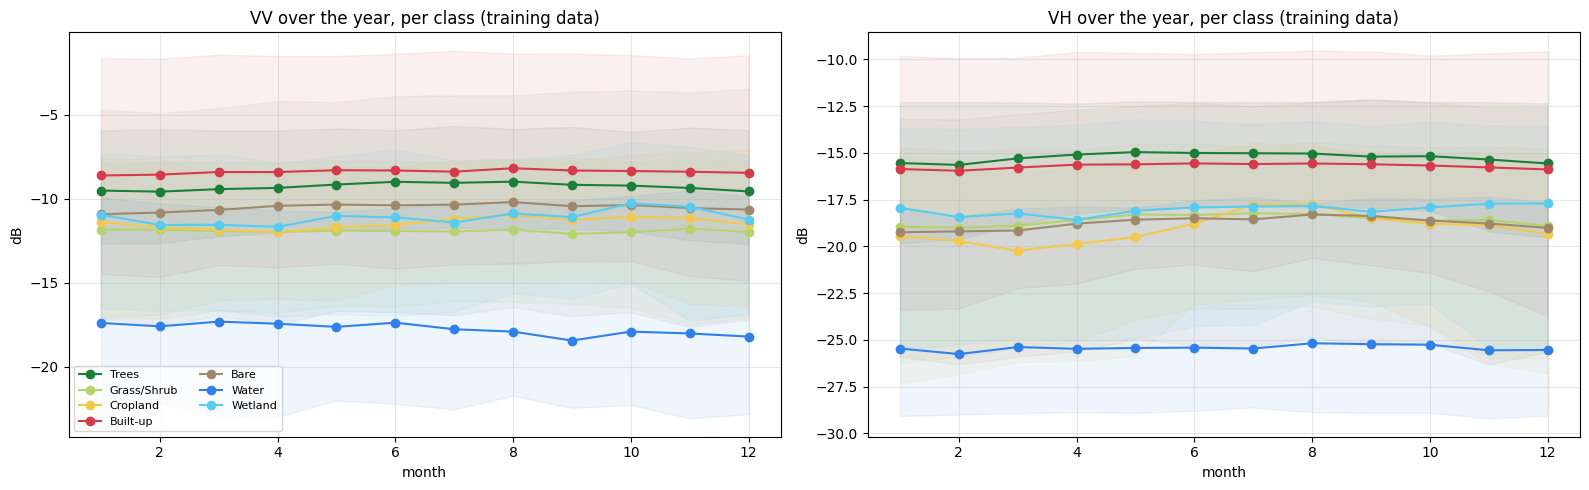

In [5]:
files = index[index.split == "train"].file
files = files.sample(min(120, len(files)), random_state=0)
curves = {c: [] for c in range(len(CLASSES))}
rng = np.random.default_rng(0)
for f in files:
    d = np.load(DATA / f); x, y = d["x"].astype(np.float32), d["y"]
    for c in range(len(CLASSES)):
        r, cc = np.nonzero(y == c)
        if len(r):
            k = rng.choice(len(r), min(40, len(r)), replace=False)
            curves[c].append(x[:, :2, r[k], cc[k]])               # (12, 2, n)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for c, col in enumerate(COLORS):
    if not curves[c]: continue
    v = np.concatenate(curves[c], 2)
    for b, name in enumerate(["VV", "VH"]):
        med = np.nanmedian(v[:, b], 1); lo, hi = np.nanpercentile(v[:, b], [10, 90], 1)
        ax[b].plot(range(1, 13), med, color=col, marker="o", label=CLASSES[c]); ax[b].fill_between(range(1, 13), lo, hi, color=col, alpha=0.08)
for b, name in enumerate(["VV", "VH"]):
    ax[b].set_title(f"{name} over the year, per class (training data)"); ax[b].set_xlabel("month"); ax[b].set_ylabel("dB"); ax[b].grid(alpha=0.3)
ax[0].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.savefig(RUN / "class_curves.png", dpi=120); plt.show()

## 4. Data and model

In [6]:
train_dl, val_dl = make_loaders(CFG, DATA, index)
model = build_model(CFG, mstats, ystats, CFG["WEIGHTS"]).to(DEV)
loss_fn = make_loss(CFG, mstats)
print(f"parameters: {count_params(model):.1f} M  (v5: 24.7 M) - temporal encoder + fusion: "
      f"{(count_params(model.temporal) + count_params(model.fuse)) * 1000:.1f} k")

# quick check: one batch through the model
x, m, y = next(iter(train_dl))
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    out = model(x.to(DEV), m.to(DEV))
print("input", tuple(x.shape), "(batch, months, bands, H, W) | output", tuple(out.shape), "(batch, classes, H, W)")

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

train patches 950 | val patches 128 (x 12 months each)


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

parameters: 24.8 M  (v5: 24.7 M) - temporal encoder + fusion: 7.1 k
input (8, 12, 3, 256, 256) (batch, months, bands, H, W) | output (8, 7, 256, 256) (batch, classes, H, W)


## 5. Train
Resumes automatically from `last.pth` if the kernel stops. One epoch ≈ a few minutes on the GPU.

In [7]:
history = train(model, CFG, RUN, train_dl, val_dl, loss_fn)

epoch 0:   0%|          | 0/118 [00:00<?, ?it/s]

ep  0 | train 1.916 | val 1.633 | OA 0.696 | mIoU 0.470  *best* | 81s


epoch 1:   0%|          | 0/118 [00:00<?, ?it/s]

ep  1 | train 1.325 | val 1.634 | OA 0.684 | mIoU 0.464 | 68s


epoch 2:   0%|          | 0/118 [00:00<?, ?it/s]

ep  2 | train 1.140 | val 1.687 | OA 0.681 | mIoU 0.484  *best* | 67s


... (84 outputs left out)

epoch 45:   0%|          | 0/118 [00:00<?, ?it/s]

ep 45 | train 0.567 | val 1.147 | OA 0.828 | mIoU 0.632 | 67s


epoch 46:   0%|          | 0/118 [00:00<?, ?it/s]

ep 46 | train 0.556 | val 1.175 | OA 0.817 | mIoU 0.623 | 67s
Early stopping.
Done. Best val mIoU: 0.6499


## 6. Results on validation (best checkpoint)

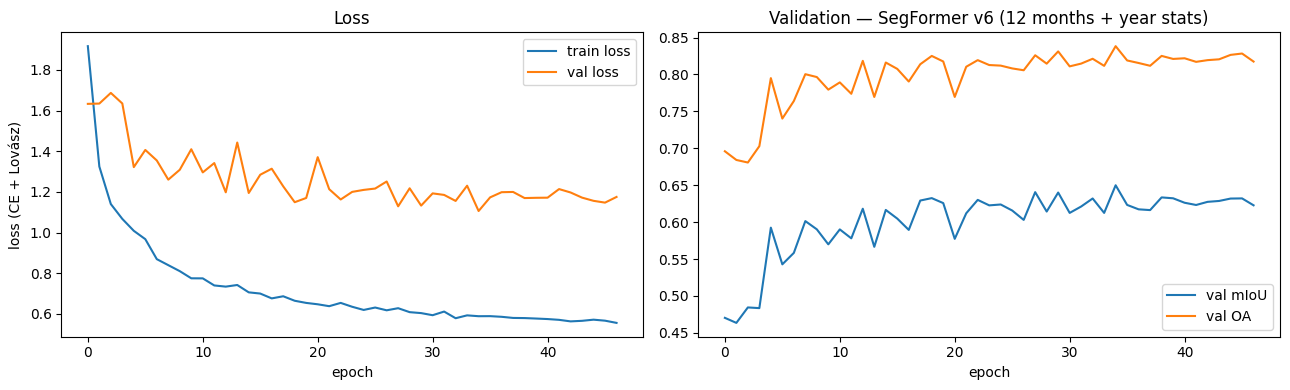

SegFormer v6 (12 months + year stats) - val: OA 0.838 | mIoU 0.650 | best / worst month mIoU 0.651 / 0.649 (spread 0.002)


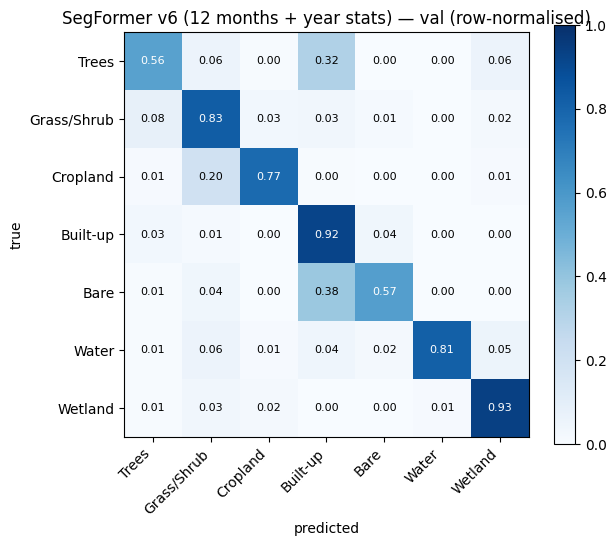

Validation, v5 vs v6


,v5 IoU,v6 IoU,change
Trees,0.413,0.441,0.028
Grass/Shrub,0.676,0.705,0.029
Cropland,0.661,0.693,0.032
Built-up,0.780,0.790,0.010
Bare,0.266,0.291,0.025
Water,0.737,0.751,0.014
Wetland,0.851,0.879,0.028
mIoU,0.626,0.650,0.024


In [8]:
plot_curves(RUN, CFG["MODEL_NAME"])
model.load_state_dict(torch.load(RUN / "best.pth", map_location=DEV))
val_table, val_month = report(model, CFG, RUN, val_dl, "val")

v5 = json.load(open("runs/C_segformer_v5/metrics.json"))
cmp = pd.DataFrame({"v5 IoU": pd.Series(v5["per_class_iou"]), "v6 IoU": val_table["IoU"].drop("mean")})
cmp.loc["mIoU"] = [v5["val_miou"], val_table.loc["mean", "IoU"]]
cmp["change"] = cmp["v6 IoU"] - cmp["v5 IoU"]
print("Validation, v5 vs v6"); display(cmp.round(3))

## 7. Do the months differ now?
v5's maps were almost identical in every month. Below: mIoU per month (validation) and four months of one validation tile.

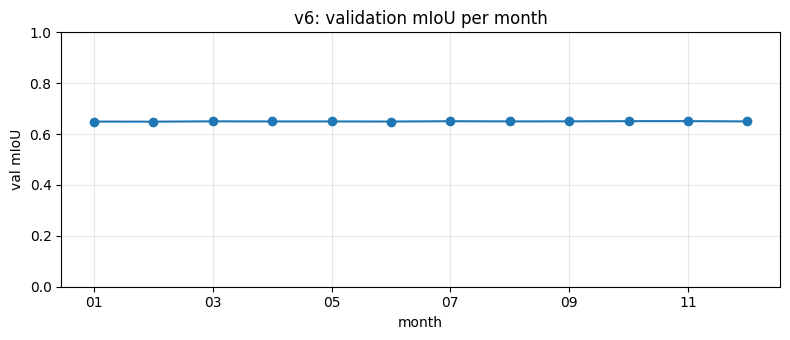

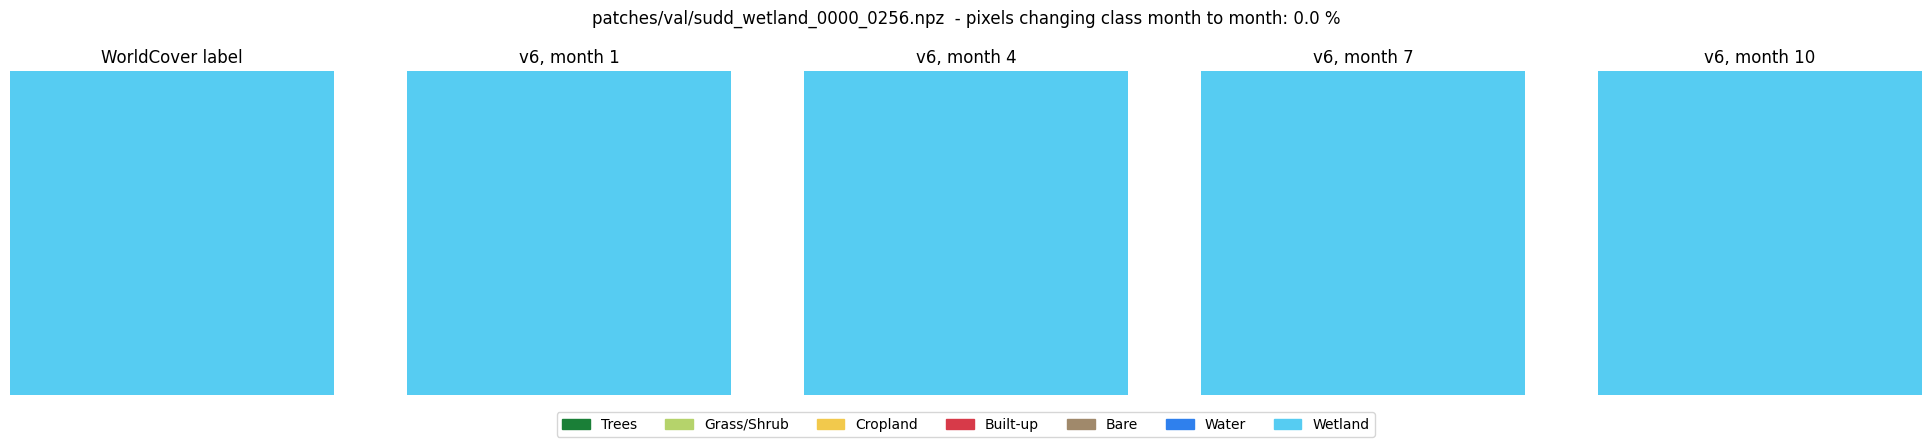

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
val_month.plot(ax=ax, marker="o"); ax.set_ylim(0, 1); ax.set_xlabel("month"); ax.set_ylabel("val mIoU"); ax.grid(alpha=0.3)
ax.set_title("v6: validation mIoU per month"); plt.tight_layout(); plt.show()

from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
ds = val_dl.dataset
k = int(np.argmax([float((y_ == 2).float().mean() + (y_ == 6).float().mean()) for y_ in ds.ys]))   # a tile with crop / wetland
x, y = ds[k]
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    e = model.encode(x[None].to(DEV))
    preds = [model.decode(e, torch.tensor([m], device=DEV)).argmax(1)[0].cpu().numpy() for m in range(12)]
changed = np.mean([(preds[m] != preds[m - 1]).mean() for m in range(1, 12)]) * 100
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); ax[0].set_title("WorldCover label")
for a, m in zip(ax[1:], [0, 3, 6, 9]):
    a.imshow(preds[m], cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); a.set_title(f"v6, month {m + 1}")
for a in ax: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
fig.suptitle(f"{ds.files[k]}  - pixels changing class month to month: {changed:.1f} %")
plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.savefig(RUN / "val_months_example.png", dpi=110); plt.show()

## 8. Test set (final exam — only for reporting, not for choosing settings)
v5 on the same 6 test regions: **OA 0.837, mIoU 0.722** (Trees .686, Grass .487, Crop .716, Built-up .828, Bare .970, Water .819, Wetland .547).

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

SegFormer v6 (12 months + year stats) - test: OA 0.842 | mIoU 0.730 | best / worst month mIoU 0.733 / 0.728 (spread 0.005)


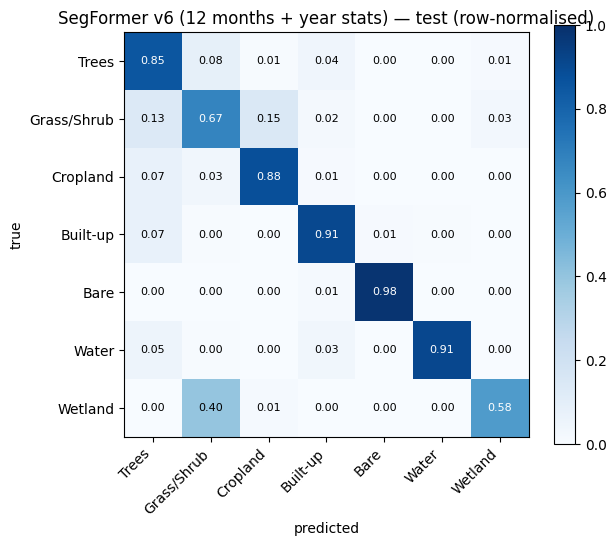

,v5 IoU,v6 IoU,change
Trees,0.686,0.695,0.009
Grass/Shrub,0.487,0.503,0.016
Cropland,0.716,0.714,-0.002
Built-up,0.828,0.842,0.014
Bare,0.970,0.969,-0.001
Water,0.819,0.848,0.029
Wetland,0.547,0.540,-0.007
mIoU,0.722,0.730,0.008


saved: ['best.pth', 'class_curves.png', 'config.json', 'curves.png', 'history.csv', 'last.pth', 'metrics.json', 'test_confusion.png', 'test_per_class.csv', 'val_confusion.png', 'val_months_example.png', 'val_per_class.csv']


In [10]:
test_ds = EvalSeries(index[index.split == "test"].file, DATA, "loading test")
test_dl = torch.utils.data.DataLoader(test_ds, CFG["EVAL_BATCH"], shuffle=False)
test_table, test_month = report(model, CFG, RUN, test_dl, "test")
v5_test = pd.Series({"Trees": .686, "Grass/Shrub": .487, "Cropland": .716, "Built-up": .828, "Bare": .970, "Water": .819, "Wetland": .547})
t = pd.DataFrame({"v5 IoU": v5_test, "v6 IoU": test_table["IoU"].drop("mean")})
t.loc["mIoU"] = [0.722, test_table.loc["mean", "IoU"]]; t["change"] = t["v6 IoU"] - t["v5 IoU"]
display(t.round(3))
print("saved:", sorted(p.name for p in RUN.iterdir()))

✅ **Share with me:** the training curves, the two v5-vs-v6 tables, the per-month plot and the 4-month example.
If v6 is better, the next step is to let notebook 15 (test any place) and the prototype use v6 — `predict_region()` in `train_lib_r6.py` is already prepared for that.